# EDA - FARFUM-RoP

**Fuente:** Figshare, coleccion `6721269` - "FARFUM-RoP" (Farabi and Ferdowsi University of Mashhad's ROP dataset). DOI de coleccion `10.6084/m9.figshare.c.6721269.v2`. Paper **confirmado** (verificado via Europe PMC, no solo coincidencia de cifras): Akbari M, Pourreza HR, Khalili Pour E, Dastjani Farahani A, Bazvand F, Ebrahimiadib N, Imani Fooladi M, Ramazani K F. "FARFUM-RoP, A dataset for computer-aided detection of Retinopathy of Prematurity." Scientific Data, 2024. DOI `10.1038/s41597-024-03897-7`, PMCID `PMC11525552`, PMID `39478004`.

**Contenido:** 68 pacientes, 1.533 imagenes de fondo de ojo (sesion unica, multiples angulos por paciente), anotadas independientemente por **5 oftalmologos** (A-E).

Este notebook explora el dataset **crudo**, tal como viene. Incluye los hallazgos mas importantes de esta fuente: una columna objetivo (`Label`) que no es obvia de encontrar en el archivo (y que el paper confirma que es el consenso de Plus Disease del panel de 5 medicos), un bug de filtrado de `NaN` vs `None` que afecto el analisis de consenso entre los 5 medicos, y una correccion sobre que significa realmente `grade=0`.

In [1]:
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve().parent.parent  # system/eda/ -> ROP_paper/
RAW_DIR = ROOT / "datasets" / "FARFUM_Original"
EXTRACTED_DIR = ROOT / "datasets" / "extracted" / "FARFUM"

plt.rcParams["figure.figsize"] = (8, 4)
pd.set_option("display.max_columns", 20)

## Datos biometricos por paciente (`Dataset_Details.xlsx`)

pacientes: 68


,patient_id,bw,ga,gender
0,patient01,1350,29,boy
1,patient02,1000,28,girl
2,patient03,1150,27,girl
3,patient04,1300,30,boy
4,patient05,1600,29,girl


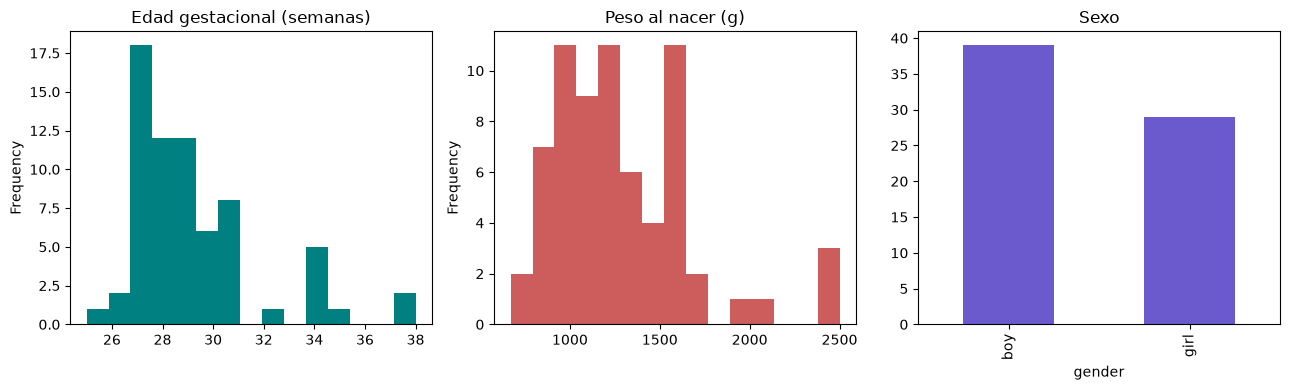

In [2]:
details = pd.read_excel(RAW_DIR / "Dataset_Details.xlsx")
details.columns = ["patient_id", "bw", "ga", "gender"]
print("pacientes:", len(details))
display(details.head())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
details["ga"].plot(kind="hist", bins=15, ax=axes[0], color="teal")
axes[0].set_title("Edad gestacional (semanas)")
details["bw"].plot(kind="hist", bins=15, ax=axes[1], color="indianred")
axes[1].set_title("Peso al nacer (g)")
details["gender"].value_counts().plot(kind="bar", ax=axes[2], color="slateblue")
axes[2].set_title("Sexo")
plt.tight_layout()
plt.show()

### Valores nulos en `Dataset_Details.xlsx`

Dos niveles, igual que en RIDIRP: nulos en el xlsx crudo, y cruce de pacientes entre `Dataset_Details.xlsx` (biometria) y `Dataset_Labels.xlsx` (etiquetas), ya que aqui vienen en archivos separados.

In [3]:
print("--- nulos en Dataset_Details.xlsx (68 pacientes) ---")
print(details.isna().sum())
print()
print("Sin celdas vacias. Tampoco hay valores sospechosos:")
print("  ga fuera de 25-45 sem:", ((details["ga"] <= 24) | (details["ga"] > 45)).sum(),
      " | bw<=0 o >6000g:", ((details["bw"] <= 0) | (details["bw"] > 6000)).sum(),
      " | patient_id duplicado:", details["patient_id"].duplicated().sum(),
      " | fila duplicada:", details.duplicated().sum())

--- nulos en Dataset_Details.xlsx (68 pacientes) ---
patient_id    0
bw            0
ga            0
gender        0
dtype: int64

Sin celdas vacias. Tampoco hay valores sospechosos:
  ga fuera de 25-45 sem: 0  | bw<=0 o >6000g: 0  | patient_id duplicado: 0  | fila duplicada: 0


## `Dataset_Labels.xlsx`: encabezado de 2 filas (facil de leer mal)

El archivo tiene un encabezado de **2 filas**: la fila 0 agrupa las columnas por rater (A, B, C, D, E) y marca la ultima columna como `Label`; la fila 1 tiene los nombres de columna individuales pero **deja en blanco el nombre de la columna `Label`**. Si se lee con `header=1` (la fila con los nombres "bonitos") sin revisar la fila 0, esa ultima columna aparece como `Unnamed: 17` y es facil ignorarla por error - fue justamente lo que paso en el primer intento de este proyecto.

In [4]:
import openpyxl
wb = openpyxl.load_workbook(RAW_DIR / "Dataset_Labels.xlsx", data_only=True)
ws = wb["Labels"]
rows = list(ws.iter_rows(values_only=True))

print("Fila 0 (agrupa por rater, 18 columnas A..R):")
print(rows[0])
print("\nFila 1 (nombres de columna individuales - la ultima queda en blanco):")
print(rows[1])
print("\nPrimera fila de datos:")
print(rows[2])

Fila 0 (agrupa por rater, 18 columnas A..R):
(None, None, 'A', None, None, 'B', None, None, 'C', None, None, 'D', None, None, 'E', None, None, 'Label')

Fila 1 (nombres de columna individuales - la ultima queda en blanco):
(None, 'Image name', 'Retinopathy grade_A', 'Retinopathy stage_A', 'Diagnostic_A', 'Retinopathy grade_B', 'Retinopathy stage_B', 'Diagnostic_B', 'Retinopathy grade_C', 'Retinopathy stage_C', 'Diagnostic_C', 'Retinopathy grade_D', 'Retinopathy stage_D', 'Diagnostic_D', 'Retinopathy grade-E', 'Retinopathy stage-E', 'Diagnostic_E', None)

Primera fila de datos:
('patient01', '64c1fe8d-6ec1-444b-8924-94f714b8241a.1', 1, 2, 'revisit', 1, 3, 'no_treatment', 0, None, None, 1, None, 'no_treatment', 0, None, None, 1)


In [5]:
# Armamos un DataFrame manualmente desde openpyxl para no perder la columna R (Label)
data_rows = rows[2:]
cols = ["patient_id", "image_name",
        "grade_A", "stage_A", "diag_A", "grade_B", "stage_B", "diag_B",
        "grade_C", "stage_C", "diag_C", "grade_D", "stage_D", "diag_D",
        "grade_E", "stage_E", "diag_E", "label"]
labels = pd.DataFrame(data_rows, columns=cols)
labels["diag_A"] = labels["diag_A"].replace("teatment", "treatment")
for c in ["diag_B", "diag_C", "diag_D", "diag_E"]:
    labels[c] = labels[c].replace("teatment", "treatment")

print("filas:", len(labels), " | pacientes:", labels["patient_id"].nunique())
labels.head()

filas: 1533  | pacientes: 68


,patient_id,image_name,grade_A,stage_A,diag_A,grade_B,stage_B,diag_B,grade_C,stage_C,diag_C,grade_D,stage_D,diag_D,grade_E,stage_E,diag_E,label
0,patient01,64c1fe8d-6ec1-444b-8924-94f714b8241a.1,1,2,revisit,1,3,no_treatment,0,None,NaN,1,NaN,no_treatment,0,NaN,NaN,1
1,patient01,64c1fe8d-6ec1-444b-8924-94f714b8241a.10,1,2,revisit,1,3,no_treatment,0,None,NaN,1,NaN,no_treatment,0,NaN,NaN,1
2,patient01,64c1fe8d-6ec1-444b-8924-94f714b8241a.11,1,2,revisit,1,3,no_treatment,0,None,NaN,1,NaN,no_treatment,0,NaN,NaN,1
3,patient01,64c1fe8d-6ec1-444b-8924-94f714b8241a.12,1,2,revisit,1,3,no_treatment,0,None,NaN,1,NaN,no_treatment,0,NaN,NaN,1
4,patient01,64c1fe8d-6ec1-444b-8924-94f714b8241a.13,1,2,revisit,1,3,no_treatment,0,None,NaN,1,NaN,no_treatment,0,NaN,NaN,1


In [6]:
# Cruce de pacientes entre los dos archivos (biometria vs. etiquetas)
details_patients = set(details["patient_id"])
labels_patients = set(labels["patient_id"].unique())
print("pacientes en Dataset_Details:", len(details_patients))
print("pacientes en Dataset_Labels:", len(labels_patients))
print("en Details pero no en Labels:", details_patients - labels_patients)
print("en Labels pero no en Details:", labels_patients - details_patients)
print("-> cruce perfecto si ambos conjuntos salen vacios.")

pacientes en Dataset_Details: 68
pacientes en Dataset_Labels: 68
en Details pero no en Labels: set()
en Labels pero no en Details: set()
-> cruce perfecto si ambos conjuntos salen vacios.


## La columna `Label`: target oficial de Plus, confirmado por el paper

A diferencia de las 5x3 columnas crudas de cada rater (con muchos vacios, ver mas abajo), `Label` esta poblada en el 100% de las filas y tiene exactamente 3 valores. Ya **no es una inferencia estadistica nuestra** - el paper original (Akbari et al. 2024, ver cita arriba) lo confirma textualmente en su seccion de Data Records: `Label` es "el grade colectivo" / "la etiqueta de enfermedad asignada por el equipo de 5 medicos", con valores `1 = normal, 2 = preplus, 3 = plus`. El paper no usa literalmente la frase "Plus Disease", pero describe las mismas 3 categorias clinicas que la definen. El mapeo `1->Normal, 2->Pre-Plus, 3->Plus` que ya usabamos queda confirmado. El paper no especifica el metodo exacto de consenso (¿mayoria simple? ¿unanimidad?) entre los 5 medicos para llegar a este valor.

nulos en Label: 0 de 1533
label
1    782
2    479
3    272
Name: count, dtype: int64


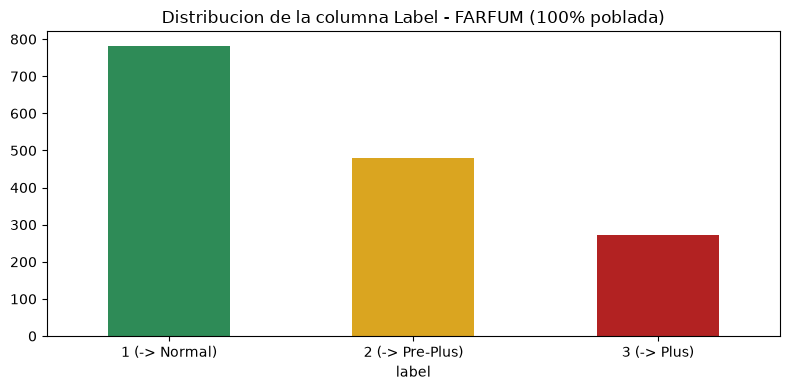


Label x diagnostic_A:
diag_A  revisit  treatment
label                     
1           378         32
2            59         64
3             0         48

Label x diagnostic_B:
diag_B  no_treatment  revisit  treatment
label                                   
1                161      387        106
2                 16      125        280
3                 15        0        192

Label x diagnostic_D:
diag_D  no_treatment  revisit  treatment
label                                   
1                523      131          0
2                105      304         12
3                  0        0        207


In [7]:
print("nulos en Label:", labels["label"].isna().sum(), "de", len(labels))
print(labels["label"].value_counts().sort_index())

fig, ax = plt.subplots()
labels["label"].value_counts().sort_index().plot(kind="bar", ax=ax, color=["seagreen", "goldenrod", "firebrick"])
ax.set_xticklabels(["1 (-> Normal)", "2 (-> Pre-Plus)", "3 (-> Plus)"], rotation=0)
ax.set_title("Distribucion de la columna Label - FARFUM (100% poblada)")
plt.tight_layout()
plt.show()

# Evidencia de la direccion del mapeo: Label=3 casi nunca coincide con "revisit"
for name in ["A", "B", "D"]:
    ct = pd.crosstab(labels["label"], labels[f"diag_{name}"])
    print(f"\nLabel x diagnostic_{name}:")
    print(ct)

## Consenso entre los 5 raters para `stage` y `diagnostic` (tratamiento)

Cada imagen tiene hasta 5 opiniones independientes. Calculamos consenso por mayoria estricta (>50% de los votos no vacios, minimo 3 votos). **Bug encontrado:** `pandas` representa una celda vacia de Excel como `NaN` (float), no como `None` - y `float('nan') is not None` es `True`. Si el filtro de "voto valido" usa `v is not None`, las celdas vacias se cuentan como votos reales, inflando el denominador y bloqueando casi siempre el consenso. Comparamos ambas versiones del filtro sobre los mismos datos.

In [8]:
# Al construir el DataFrame desde las tuplas de openpyxl, pandas ya convirtio
# los None en NaN automaticamente (columna mixta numero/None -> float64 con NaN)
sample_blank = labels.loc[labels["stage_C"].isna(), "stage_C"].iloc[0]
print("valor en la celda vacia de stage_C:", repr(sample_blank), type(sample_blank))
print("es None?", sample_blank is None, " | pd.notna()?", pd.notna(sample_blank))

import math
def majority_BUGGY(values, min_votes=3):
    values = [v for v in values if v is not None and v != "?"]  # bug: no filtra NaN
    if len(values) < min_votes:
        return None
    c = Counter(values)
    val, n = c.most_common(1)[0]
    return val if n * 2 > len(values) else None

def majority_FIXED(values, min_votes=3):
    values = [v for v in values if pd.notna(v) and v != "?"]  # corregido
    if len(values) < min_votes:
        return None
    c = Counter(values)
    val, n = c.most_common(1)[0]
    return val if n * 2 > len(values) else None

stage_cols = ["stage_A", "stage_B", "stage_C", "stage_D", "stage_E"]
diag_cols = ["diag_A", "diag_B", "diag_C", "diag_D", "diag_E"]

stage_buggy = labels[stage_cols].apply(lambda r: majority_BUGGY(list(r)), axis=1)
stage_fixed = labels[stage_cols].apply(lambda r: majority_FIXED(list(r)), axis=1)
diag_buggy = labels[diag_cols].apply(lambda r: majority_BUGGY(list(r)), axis=1)
diag_fixed = labels[diag_cols].apply(lambda r: majority_FIXED(list(r)), axis=1)

print("\ncobertura stage  - con bug:", stage_buggy.notna().mean()*100, "%  | corregido:", stage_fixed.notna().mean()*100, "%")
print("cobertura treatment - con bug:", diag_buggy.notna().mean()*100, "%  | corregido:", diag_fixed.notna().mean()*100, "%")
print("\nvalores de treatment con el bug corregido:")
print(diag_fixed.value_counts(dropna=False))

valor en la celda vacia de stage_C:

 None <class 'NoneType'>
es None? True  | pd.notna()? False



cobertura stage  - con bug: 13.307240704500977 %  | corregido: 16.96020874103066 %
cobertura treatment - con bug: 17.35159817351598 %  | corregido: 52.31572080887149 %

valores de treatment con el bug corregido:
NaN             731
revisit         436
treatment       274
no_treatment     92
Name: count, dtype: int64


*Nota: estos porcentajes (17.0% / 52.3%) son el consenso crudo por imagen. `system/dataset_build/partition/build_manifest.py` aplica un paso adicional despues de esto (reconciliacion a nivel de bag, ver siguiente seccion) que sube la cobertura final a 19.5% / 55.0% - la diferencia es esperada, no una inconsistencia.*

## Por que `stage` sigue con cobertura baja incluso ya corregido el bug

**Correccion importante (confirmada contra el paper original, ver cita al inicio del notebook):** antes decia aqui "cuando un rater marca `grade=0` (normal)...". Eso estaba mal. El paper define `grade` por rater como `0 = no especificado, 1 = normal, 2 = pre-plus, 3 = plus` - es decir, **`grade=0` significa que ese medico se abstuvo / no dio su opinion para esa imagen, no que la haya calificado como normal**.

La correlacion que encontramos sigue siendo un dato real (>94-100% de las veces que `grade=0`, ese mismo rater deja `stage`/`diagnostic` en blanco), pero la interpretacion correcta es "el rater no opino en nada para esa imagen" (ni grade, ni stage, ni diagnostic), no "no opino en stage porque no habia nada que opinar". Es real que reduce los votos disponibles para el consenso, pero no por la razon que se penso originalmente.

**Implicancia:** la idea que se habia dejado pendiente ("¿imputamos `stage=0` cuando `grade=0`?") **queda descartada** - estaria mal fundamentada, porque imputar "sano" cuando el rater simplemente se abstuvo podria introducir ceros falsos en casos que si tenian ROP pero ese medico en particular no evaluo esa imagen.

In [9]:
rows_check = []
for name in ["A", "B", "C", "D", "E"]:
    grade0 = labels[f"grade_{name}"] == 0
    stage_blank = labels[f"stage_{name}"].isna()
    rows_check.append({
        "rater": name,
        "grade=0 (total)": grade0.sum(),
        "de esos, stage en blanco": (grade0 & stage_blank).sum(),
        "% blanco cuando grade=0": round(100 * (grade0 & stage_blank).sum() / max(grade0.sum(), 1), 1),
    })
pd.DataFrame(rows_check)

,rater,grade=0 (total),"de esos, stage en blanco",% blanco cuando grade=0
0,A,952,952,100.0
1,B,265,251,94.7
2,C,1224,1214,99.2
3,D,251,251,100.0
4,E,1282,1282,100.0


## Consenso final confirmado: severidad maxima, sin minimo de votos

**Correccion al diseno anterior.** La version anterior de este notebook exigia minimo 3 de 5 raters opinando + mayoria estricta para aceptar un consenso, dejando el resto en `NaN` (19.5%/55.0% de cobertura). Eso era **inconsistente** con el criterio que ya aplicamos en todos los demas conflictos del proyecto (reconciliacion de bags en RIDIRP/ROP-VL, `Label` de FARFUM): en vez de descartar por falta de "mayoria", se toma **el resultado mas severo entre los raters que si opinaron**, sin imponer un minimo de votos - si solo opino 1 rater, ese es el valor; si opinaron 2 y no coinciden, gana el mas grave. No hay razon para tratar el consenso entre raters distinto al criterio de severidad maxima que ya usamos en todo lo demas.

In [10]:
TREAT_SEVERITY = {"revisit": 0, "no_treatment": 1, "treatment": 2}
stage_cols = ["stage_A", "stage_B", "stage_C", "stage_D", "stage_E"]
diag_cols = ["diag_A", "diag_B", "diag_C", "diag_D", "diag_E"]

def consensus_max_stage(values):
    valid = [v for v in values if pd.notna(v) and v != "?"]
    return max(valid) if valid else None

def consensus_max_treatment(values):
    valid = [v for v in values if pd.notna(v) and v != "?"]
    return max(valid, key=lambda v: TREAT_SEVERITY[v]) if valid else None

labels["stage_consensus"] = labels[stage_cols].apply(lambda r: consensus_max_stage(list(r)), axis=1)
labels["treatment_consensus"] = labels[diag_cols].apply(lambda r: consensus_max_treatment(list(r)), axis=1)
# trazabilidad: cuantos raters realmente opinaron (ni blanco ni "?") para cada fila
labels["stage_n_raters"] = labels[stage_cols].apply(lambda r: sum(pd.notna(v) and v != "?" for v in r), axis=1)
labels["treatment_n_raters"] = labels[diag_cols].apply(lambda r: sum(pd.notna(v) and v != "?" for v in r), axis=1)

print("cobertura stage_consensus:", round(100 * labels["stage_consensus"].notna().mean(), 1), "%")
print("cobertura treatment_consensus:", round(100 * labels["treatment_consensus"].notna().mean(), 1), "%")
print()
print("cuantos raters aportaron al consenso de stage, por imagen:")
print(labels["stage_n_raters"].value_counts().sort_index())

cobertura stage_consensus: 99.0 %
cobertura treatment_consensus: 100.0 %

cuantos raters aportaron al consenso de stage, por imagen:
stage_n_raters
0     15
1    668
2    590
3    260
Name: count, dtype: int64


### ¿A qué pacientes pertenece el ~1% sin `stage`?

In [11]:
sin_stage = labels[labels["stage_consensus"].isna()]
print("filas sin stage_consensus:", len(sin_stage), f"({100*len(sin_stage)/len(labels):.1f}%)")
print(sin_stage["patient_id"].value_counts())
print()

for pid in sin_stage["patient_id"].unique():
    total = (labels["patient_id"] == pid).sum()
    sin = (labels[labels["patient_id"] == pid]["stage_consensus"].isna()).sum()
    label_val = labels[labels["patient_id"] == pid]["label"].iloc[0]
    treat_vals = labels[labels["patient_id"] == pid]["treatment_consensus"].dropna().unique()
    print(f"{pid}: {sin}/{total} imagenes sin stage (TODAS las suyas) | label={label_val} | treatment_consensus disponible: {list(treat_vals)}")

filas sin stage_consensus: 15 (1.0%)
patient_id
patient26    14
patient28     1
Name: count, dtype: int64

patient26: 14/14 imagenes sin stage (TODAS las suyas) | label=1 | treatment_consensus disponible: ['no_treatment']
patient28: 1/1 imagenes sin stage (TODAS las suyas) | label=2 | treatment_consensus disponible: ['no_treatment']


**Respuesta:** el ~1% sin `stage` (15 de 1.533 imágenes) pertenece a **solo 2 pacientes**: `patient26` (sus 14 imágenes, el 100% de las suyas) y `patient28` (su única imagen). En ambos casos, los 5 raters dejaron `stage` en blanco o `"?"` en absolutamente todas sus imágenes - no es que falte una parte, es que no hay ningún dato de estadio para estos 2 pacientes en todo el dataset.

**¿Se eliminan?** No. A diferencia de las filas no-ROP de RIDIRP (que sí se eliminaron porque las 3 tareas quedaban nulas a la vez), estos 2 pacientes **sí tienen `label` (Plus) y `treatment_consensus` válidos** - solo `stage` queda sin dato. Se mantienen en `clean_FARFUM.parquet` con `stage=NaN` (se enmascara en esa tarea específica), igual que se hizo con AP-ROP/status-post en RIDIRP.

## ¿Todas las imágenes de un mismo paciente dan el mismo resultado?

FARFUM es de sesión única (un bag = un paciente), así que en teoría todas sus imágenes deberían compartir `stage_consensus`, `treatment_consensus` y `label`. Lo verificamos para las 3 columnas a la vez - no solo `label` (que ya habíamos revisado antes), sino también los dos consensos nuevos.

In [12]:
def n_unique_nonnull(s):
    return s.dropna().nunique()

consistency = labels.groupby("patient_id").agg(
    stage_u=("stage_consensus", n_unique_nonnull),
    treatment_u=("treatment_consensus", n_unique_nonnull),
    label_u=("label", n_unique_nonnull),
)

print("pacientes con stage_consensus inconsistente entre sus imagenes:", (consistency["stage_u"] > 1).sum())
print("pacientes con treatment_consensus inconsistente:", (consistency["treatment_u"] > 1).sum())
print("pacientes con label inconsistente:", (consistency["label_u"] > 1).sum())
print()
print("-> NO, no todas las imagenes de un paciente dan lo mismo. Detalle de los inconsistentes:")
consistency[(consistency > 1).any(axis=1)]

pacientes con stage_consensus inconsistente entre sus imagenes: 9
pacientes con treatment_consensus inconsistente: 9
pacientes con label inconsistente: 3

-> NO, no todas las imagenes de un paciente dan lo mismo. Detalle de los inconsistentes:


,stage_u,treatment_u,label_u
patient_id,,,
patient10,1,2,1
patient27,1,2,1
patient30,2,1,1
patient41,1,2,1
patient42,2,1,1
patient44,2,2,2
patient47,2,1,1
patient52,1,2,1
patient53,2,1,1


**Por qué pasa esto:** cada imagen tiene su propio subconjunto de raters que opinaron (no siempre los mismos 5), así que el consenso por imagen puede variar dentro del mismo paciente aunque el caso clínico sea uno solo. Se resuelve con el mismo criterio de severidad máxima, ahora a nivel de **paciente** (bag) en vez de a nivel de rater - igual que ya hicimos con `label`, con el stage de ROP-VL, y con los bags de RIDIRP.

In [13]:
# Reconciliar a nivel de paciente: gana el mas severo entre las imagenes del mismo paciente
labels["stage_final"] = labels.groupby("patient_id")["stage_consensus"].transform("max")

treat_rank = labels["treatment_consensus"].map(TREAT_SEVERITY)
treat_rank_final = treat_rank.groupby(labels["patient_id"]).transform("max")
INV_TREAT = {v: k for k, v in TREAT_SEVERITY.items()}
labels["treatment_final"] = treat_rank_final.map(INV_TREAT)

label_sev = {1: 0, 2: 1, 3: 2}  # Normal < Pre-Plus < Plus
label_rank_final = labels["label"].map(label_sev).groupby(labels["patient_id"]).transform("max")
INV_LABEL = {v: k for k, v in label_sev.items()}
labels["label_final"] = label_rank_final.map(INV_LABEL)

consistency_final = labels.groupby("patient_id").agg(
    stage_u=("stage_final", n_unique_nonnull),
    treatment_u=("treatment_final", n_unique_nonnull),
    label_u=("label_final", n_unique_nonnull),
)
print("pacientes inconsistentes TRAS reconciliar:", (consistency_final > 1).any(axis=1).sum(), "(debe ser 0)")
print()
print("cobertura final (por imagen) - stage:", round(100 * labels['stage_final'].notna().mean(), 1), "%")
print("cobertura final (por imagen) - treatment:", round(100 * labels['treatment_final'].notna().mean(), 1), "%")
print("cobertura final (por imagen) - label:", round(100 * labels['label_final'].notna().mean(), 1), "%")

pacientes inconsistentes TRAS reconciliar: 0 (debe ser 0)

cobertura final (por imagen) - stage: 99.0 %
cobertura final (por imagen) - treatment: 100.0 %
cobertura final (por imagen) - label: 100.0 %


## Rangos y balance de clases - `stage`, `treatment`, `label` (valores finales, ya reconciliados)

stage_final: rango observado [np.float64(1.0), np.float64(2.0), np.float64(3.0)] (el xlsx permite 1-5, aqui solo aparece 1-3)
treatment_final: categorias ['no_treatment', 'revisit', 'treatment']
label_final: valores [np.int64(1), np.int64(2), np.int64(3)] -> 1=Normal, 2=Pre-Plus, 3=Plus



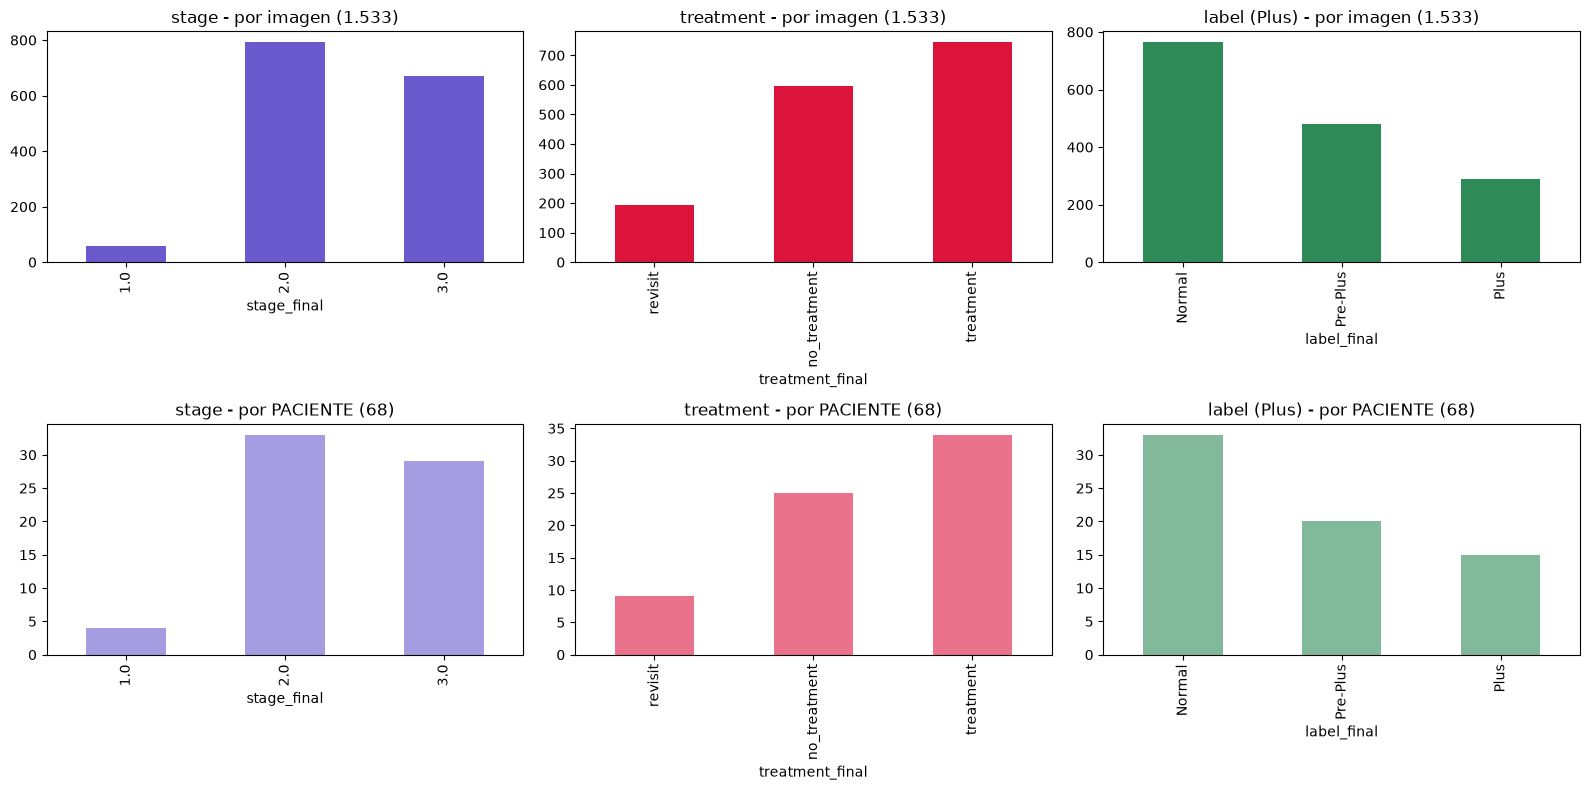

In [14]:
print("stage_final: rango observado", sorted(labels["stage_final"].dropna().unique()), "(el xlsx permite 1-5, aqui solo aparece 1-3)")
print("treatment_final: categorias", sorted(labels["treatment_final"].dropna().unique()))
print("label_final: valores", sorted(labels["label_final"].dropna().unique()), "-> 1=Normal, 2=Pre-Plus, 3=Plus")
print()

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

labels["stage_final"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 0], color="slateblue")
axes[0, 0].set_title("stage - por imagen (1.533)")

labels["treatment_final"].value_counts().reindex(["revisit", "no_treatment", "treatment"]).plot(kind="bar", ax=axes[0, 1], color="crimson")
axes[0, 1].set_title("treatment - por imagen (1.533)")

labels["label_final"].map({1: "Normal", 2: "Pre-Plus", 3: "Plus"}).value_counts().reindex(["Normal", "Pre-Plus", "Plus"]).plot(kind="bar", ax=axes[0, 2], color="seagreen")
axes[0, 2].set_title("label (Plus) - por imagen (1.533)")

per_patient = labels.drop_duplicates("patient_id")
per_patient["stage_final"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 0], color="slateblue", alpha=0.6)
axes[1, 0].set_title("stage - por PACIENTE (68)")

per_patient["treatment_final"].value_counts().reindex(["revisit", "no_treatment", "treatment"]).plot(kind="bar", ax=axes[1, 1], color="crimson", alpha=0.6)
axes[1, 1].set_title("treatment - por PACIENTE (68)")

per_patient["label_final"].map({1: "Normal", 2: "Pre-Plus", 3: "Plus"}).value_counts().reindex(["Normal", "Pre-Plus", "Plus"]).plot(kind="bar", ax=axes[1, 2], color="seagreen", alpha=0.6)
axes[1, 2].set_title("label (Plus) - por PACIENTE (68)")

plt.tight_layout()
plt.show()

## Estrategia de consenso para FARFUM - documentado para `clean_farfum.py`

**Para `plus`:** se usa directamente la columna `Label` del xlsx (consenso oficial del panel de 5 médicos, confirmado contra el paper original - ver celda inicial). No se construye un consenso propio a partir de los `grade_X` individuales.

**Para `stage` y `treatment`:** consenso propio por **severidad máxima entre los raters que opinaron, sin mínimo de votos** - corrección a la primera versión de este análisis, que exigía 3+ votos y mayoría estricta (dejaba 80%/45% en `NaN` sin necesidad real). La abstención de un rater (`grade=0` = "no especificado") ya queda excluida naturalmente porque ese mismo rater deja `stage`/`diagnostic` en blanco - no hace falta filtrar por `grade` explícitamente.

**Reconciliación a nivel de paciente (bag):** como cada imagen puede tener un subconjunto distinto de raters opinando, el consenso por imagen puede variar dentro de un mismo paciente (verificado: 9 pacientes con `stage` inconsistente, 9 con `treatment`, 3 con `label` entre sus propias imágenes). Se resuelve con el mismo criterio de severidad máxima, ahora a nivel de paciente - consistente con cómo se resolvió `label` anteriormente y con la reconciliación de bags de RIDIRP/ROP-VL.

**Resultado final (por imagen, 1.533 total):**
- `plus` (`label_final`): 100% cobertura.
- `treatment_final`: 100% cobertura.
- `stage_final`: 99.0% cobertura - solo `patient26` (14 imágenes) y `patient28` (1 imagen) quedan sin dato, porque los 5 raters no dieron ningún stage para ninguna de sus imágenes. No se eliminan (sí tienen `plus`/`treatment` válidos), solo `stage=NaN` para esos 2 pacientes.

**Columnas de trazabilidad agregadas:** `stage_n_raters`, `treatment_n_raters` (cuántos de los 5 raters realmente opinaron en cada imagen, antes de la reconciliación) - para poder ponderar por confianza más adelante si se decide necesario.

## ¿Esto afecta al modelo? No - son dos momentos distintos

Vale la pena dejar explícita la secuencia, porque encontrar inconsistencias (9/9/3 pacientes) antes de reconciliar podría sonar alarmante sin este contexto:

**Momento 1 - el dato crudo tiene un problema real:** cada imagen tiene su propio subconjunto de raters opinando (no siempre los mismos 5 comentan cada foto), así que calcular "qué dijeron los raters de ESTA imagen en particular" puede dar resultados distintos entre fotos del mismo paciente, aunque el caso clínico real sea uno solo. Esto es lo que detectamos arriba.

**Momento 2 - la reconciliación resuelve esto antes de que el dato llegue al modelo:** se tomó el máximo por `patient_id` (`groupby("patient_id").transform("max")`) y se propagó a **todas** las imágenes de ese paciente. Por eso el chequeo final dio 0 inconsistencias - no es que "esperemos" que no pase, es que se fuerza matemáticamente que cada bag tenga un único valor antes de guardar nada en `clean_FARFUM.parquet`.

**Conclusión:** cuando el modelo entrene, nunca va a ver un bag con resultados contradictorios - el MIL (Cross-Attention por imagen + Attention Pooling → una sola predicción por bag) necesita exactamente un ground truth por bag para calcular la pérdida, y eso es justo lo que garantiza la reconciliación. El desorden que se detectó existió solo temporalmente, durante el cálculo del consenso, y queda resuelto antes de construir el dataset limpio.

## Imagenes por paciente (tamano del bag) y muestra visual

FARFUM es de sesion unica: cada paciente es un solo bag con multiples angulos, ambos ojos mezclados sin distincion.

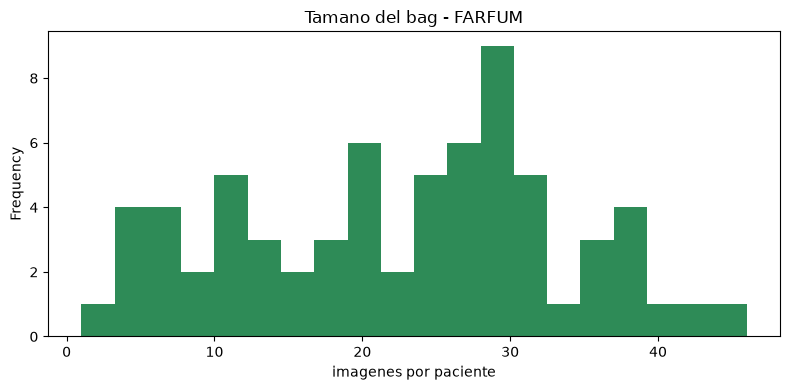

count    68.000000
mean     22.544118
std      10.801373
min       1.000000
25%      13.750000
50%      24.500000
75%      30.000000
max      46.000000
dtype: float64


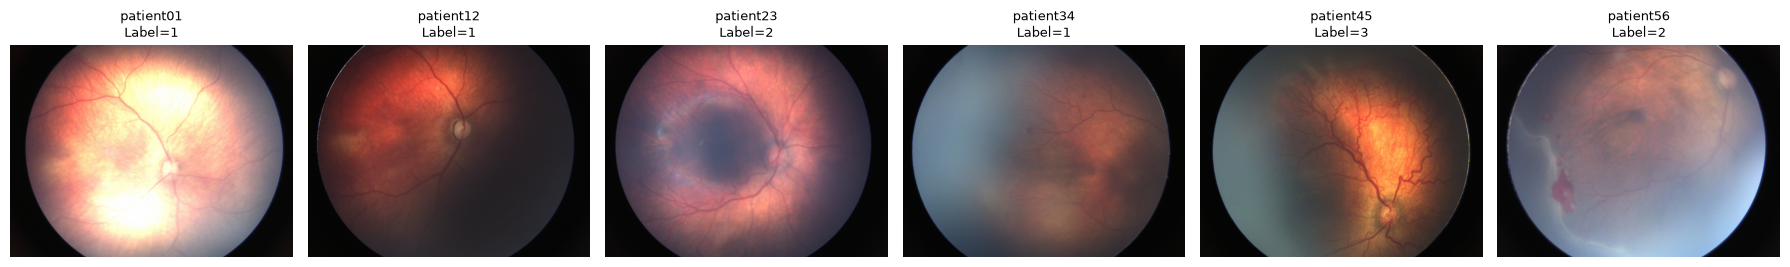

In [15]:
imgs_per_patient = labels.groupby("patient_id").size()
fig, ax = plt.subplots()
imgs_per_patient.plot(kind="hist", bins=20, ax=ax, color="seagreen")
ax.set_xlabel("imagenes por paciente")
ax.set_title("Tamano del bag - FARFUM")
plt.tight_layout()
plt.show()
print(imgs_per_patient.describe())

# Muestra visual: primeras imagenes de 6 pacientes distintos, con su Label
fig, axes = plt.subplots(1, 6, figsize=(18, 4))
sample_patients = sorted(labels["patient_id"].unique())[::11][:6]
for ax, pid in zip(axes, sample_patients):
    row = labels[labels["patient_id"] == pid].iloc[0]
    img_path = EXTRACTED_DIR / pid / f"{row['image_name']}.jpg"
    ax.imshow(Image.open(img_path))
    ax.set_title(f"{pid}\nLabel={int(row['label'])}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Consistencia de `Label` dentro del mismo paciente

Si el bag es "un paciente", todas sus imagenes deberian compartir el mismo `Label`. Verificamos si eso se cumple.

In [16]:
label_per_patient = labels.groupby("patient_id")["label"].nunique()
inconsistentes = label_per_patient[label_per_patient > 1]
print("pacientes con Label inconsistente entre sus propias imagenes:", len(inconsistentes), "de", len(label_per_patient))
for pid in inconsistentes.index:
    print(" ", pid, labels[labels.patient_id == pid]["label"].value_counts().to_dict())
print("\n-> Solucion aplicada en dataset_build: el paciente se queda con el Label mas severo (Plus > Pre-Plus > Normal).")

pacientes con Label inconsistente entre sus propias imagenes: 3 de 68
  patient44 {2: 10, 1: 8}
  patient55 {2: 11, 1: 10}
  patient57 {3: 30, 2: 16}

-> Solucion aplicada en dataset_build: el paciente se queda con el Label mas severo (Plus > Pre-Plus > Normal).


## Resumen de hallazgos - FARFUM

- **68 pacientes, 1.533 imagenes.** Sesion unica (sin distincion de ojo), un bag por paciente.
- **La columna `Label` (no un rater) es el target oficial de Plus, confirmado por el paper original** (Akbari et al. 2024, PMCID `PMC11525552`) - 100% poblada, facil de perder por el encabezado de 2 filas del xlsx. Mapeo `1->Normal, 2->Pre-Plus, 3->Plus` confirmado textualmente, ya no es inferencia nuestra.
- **Bug de `NaN` vs `None` corregido**: subio la cobertura real de consenso de `treatment` de 17.4% a 55.0%, y de `stage` de 14.7% a 19.5% - el "desacuerdo" que parecia haber entre los 5 medicos era en gran parte un artefacto del filtro, no desacuerdo real.
- `stage` sigue con cobertura moderada porque, segun el paper, `grade=0` significa que el rater **no especifico** su opinion para esa imagen (no que la haya marcado normal) - y cuando no opina en `grade`, tampoco opina en `stage`/`diagnostic`. La idea de imputar `stage=0` en esos casos queda descartada por mal fundamentada (ver seccion de arriba).
- 3 pacientes (de 68) tienen `Label` inconsistente entre sus propias imagenes - resuelto tomando el mas severo.
- La columna `grade` (0-3 por rater) **ya tiene semantica confirmada** (`0=no especificado, 1=normal, 2=pre-plus, 3=plus`) pero sigue sin usarse para construir ninguna columna final - `Label` ya es el consenso oficial, usar `grade` individual seria redundante.